In [61]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

seed = 42
key = jax.random.PRNGKey(seed)

In [62]:
def gaussian_kernel(x, z, sigma):
    """
    Computes the Gaussian kernel between two sets of points.
    """

    return jnp.exp(-(x - z) ** 2 / (2 * sigma ** 2))

In [63]:
n = 100
z = jnp.linspace(-8.0, 8.0, 1000)
sigma = 1.0

key_p, key_q = jax.random.split(key)
mean_p, var_p = 0.0, 1.0
mean_q, var_q = 1.0, 1.0

p_sample = jax.random.normal(key_p, (n,)) * jnp.sqrt(var_p) + mean_p
q_sample = jax.random.normal(key_q, (n,)) * jnp.sqrt(var_q) + mean_q

K_p = gaussian_kernel(p_sample[:, None], z[None, :], sigma)
K_q = gaussian_kernel(q_sample[:, None], z[None, :], sigma)

mu_p = jnp.mean(K_p, axis=0)
mu_q = jnp.mean(K_q, axis=0)

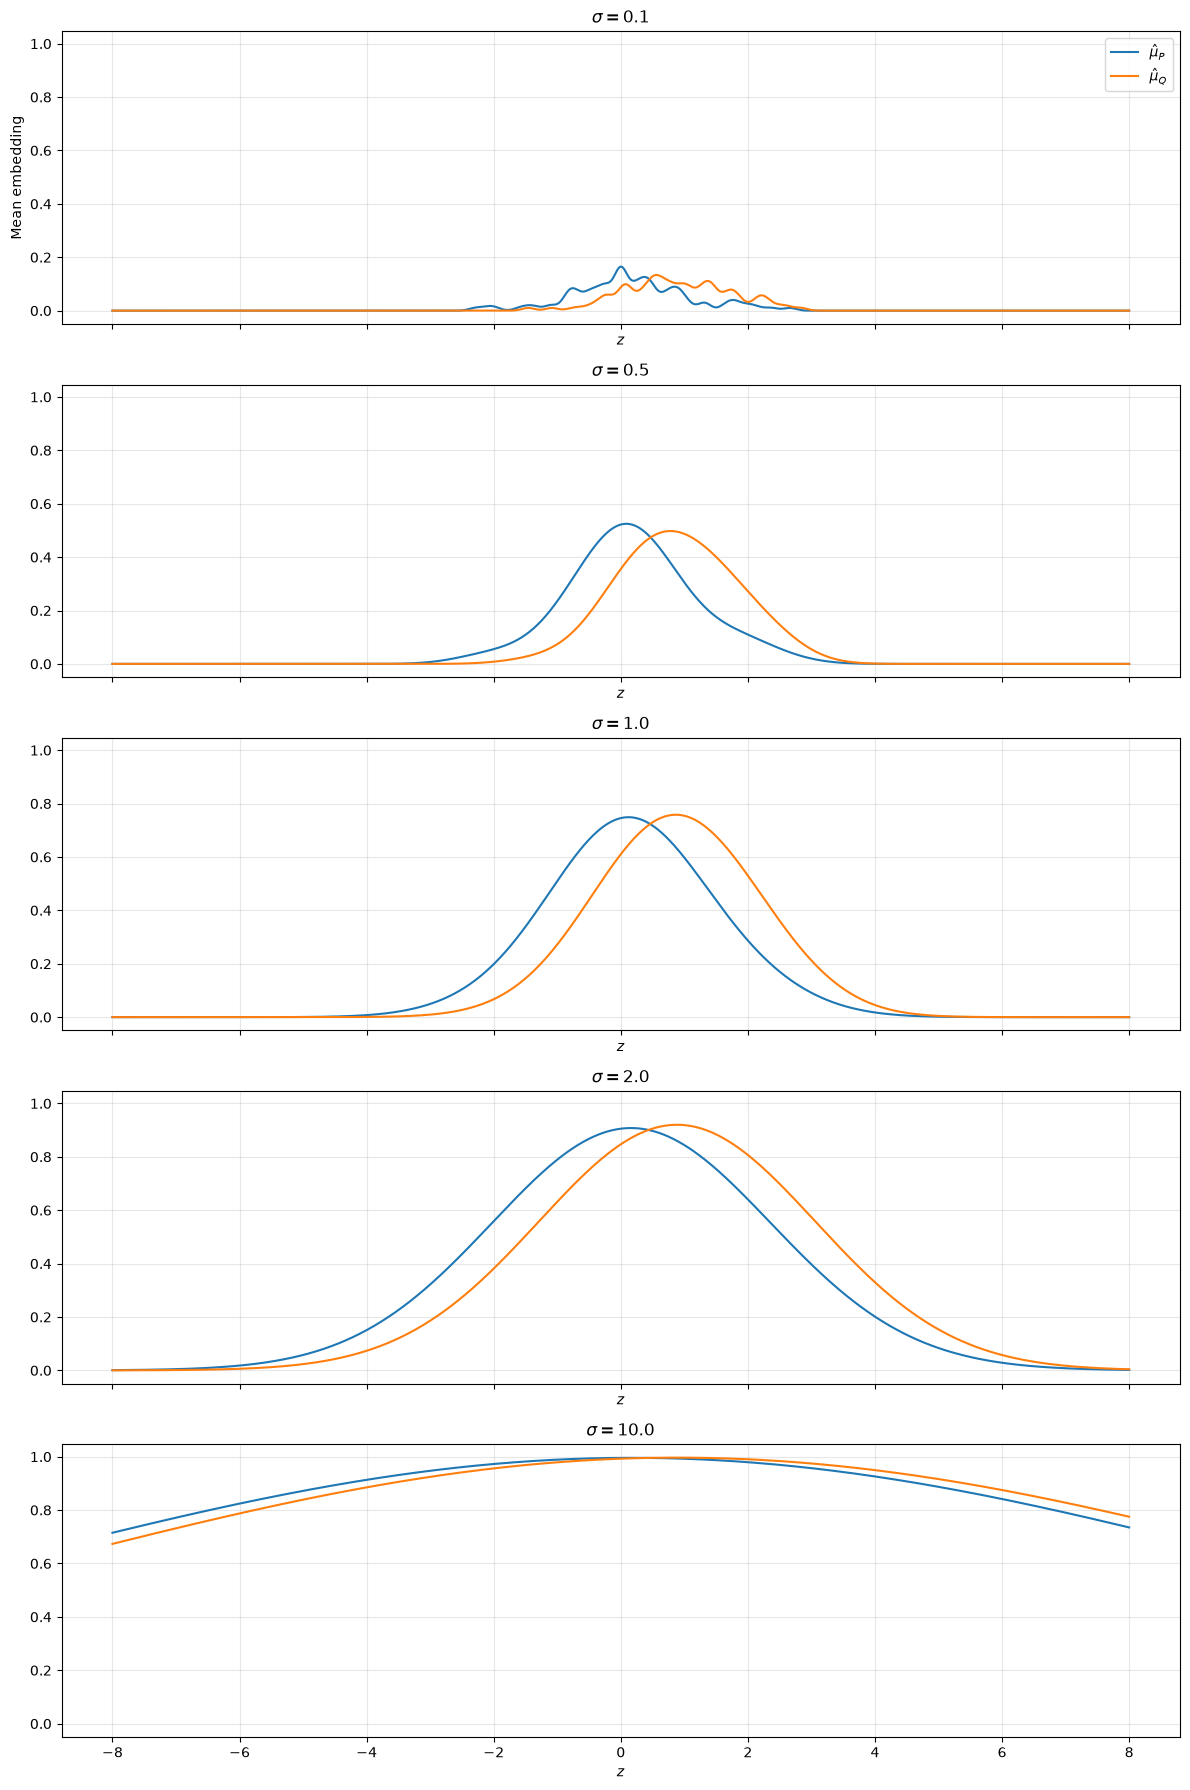

In [ ]:
bandwidths = [0.1, 0.5, 1.0, 2.0, 10.0]

fig, axes = plt.subplots(
    len(bandwidths), 1,
    figsize=(12, 18),
    sharex=True,
    sharey=True
)

for ax, sigma in zip(axes, bandwidths):
    mu_p = jnp.mean(gaussian_kernel(p_sample[:, None], z[None, :], sigma), axis=0)
    mu_q = jnp.mean(gaussian_kernel(q_sample[:, None], z[None, :], sigma), axis=0)

    ax.plot(z, mu_p, label=r"$\hat{\mu}_P$", color="tab:blue")
    ax.plot(z, mu_q, label=r"$\hat{\mu}_Q$", color="tab:orange")
    ax.set_title(rf"$\sigma = {sigma}$")
    ax.set_xlabel(r"$z$")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean embedding")
axes[0].legend()
fig.tight_layout()
plt.show()